<a href="https://colab.research.google.com/github/Antou03/Data-Trainer-Etudiants/blob/main/td_exercices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TD & Exercices — Marketing Analytics

> **À compléter** — Écrivez votre code dans les cellules `# À COMPLÉTER`.
> Les corrigés sont diffusés par le professeur après rendu.

**BIU** · Master in Strategic Sales and Marketing · Module Marketing Analytics

Ce notebook contient **5 travaux dirigés** et **8 exercices progressifs** avec **corrigés complets** (code + interprétation métier). Les données sont les mêmes que le cours (`../data/`).

> **Consigne** : pour chaque exercice, complète la cellule `# À COMPLÉTER` puis compare avec le corrigé qui suit. Barèmes indicatifs fournis.

In [ ]:
# Correction du chargement des données depuis /content/
import pandas as pd

DATA_DIR = "/content"

# Rechargement correct des DataFrames
clients = pd.read_csv(f"{DATA_DIR}/clients.csv", parse_dates=["date_inscription"])
transactions = pd.read_csv(f"{DATA_DIR}/transactions.csv", parse_dates=["date_transaction"])

print("Données chargées avec succès depuis /content/ ✓")

Données chargées avec succès depuis /content/ ✓


---
# TD 1 — Qualité des données & manipulation pandas

**Objectif** : auditer et nettoyer un jeu de données marketing.
**Durée** : 2 h · **Barème** : 20 pts

## Énoncé
Le service marketing vous transmet `clients.csv` et `transactions.csv`. Avant toute analyse, on doit s'assurer de la qualité.

### Exercice 1 (5 pts) — Audit de base
Calcule pour `clients` : nombre de lignes, nombre de colonnes, nombre de valeurs manquantes par colonne, nombre de doublons sur `client_id`.

In [ ]:
# Nombre de lignes et colonnes
print("Nombre de lignes:", clients.shape[0])
print("Nombre de colonnes:", clients.shape[1])

# Valeurs manquantes
print("\nValeurs manquantes par colonne:")
print(clients.isnull().sum())

# Doublon sur client_id
print("\nNombre de doublons sur client_id:")
print(clients.duplicated(subset="client_id").sum())

Nombre de lignes: 5000
Nombre de colonnes: 8

Valeurs manquantes par colonne:
client_id            0
genre                0
age                  0
ville                0
canal_acquisition    0
date_inscription     0
segment_marketing    0
actif                0
dtype: int64

Nombre de doublons sur client_id:
0


### Exercice 2 (5 pts) — Jointure et cohérence
Jointez `transactions` et `clients` sur `client_id`. Vérifiez qu'aucune transaction n'a perdu son client. Combien de clients n'ont effectué AUCUNE transaction ?

**INTERPRETATION**
La jointure entre les tables clients et transactions est cohérente puisqu'aucune transactionn'est associée à un client inexistant. Le ombre de transaction sans clients est égal à 0


Cependant,56 clients n'ont éffetués aucune transaction. Ces clients peuvent être ciblés par des actions marketing afin de les réactiver et les inciter à éffectuer un premier achat

In [ ]:
# Jointure clients et transactions

Jointure=transactions.merge(clients,on="client_id",how="left")

#Vérification destransactions sans client
print("Transactions sans client:",Jointure["genre"].isnull().sum())

#Clients sans transaction
clients_sans_transaction=clients[~clients["client_id"].isin(transactions["client_id"])]
print("Nombre de clients sans transaction:",len(clients_sans_transaction))

Transactions sans client: 0
Nombre de clients sans transaction: 56


### Exercice 3 (5 pts) — Création de variables dérivées
Créez dans `transactions` une colonne `annee` (année de la transaction) et `mois_lib` (nom du mois en français). Calculez le panier moyen par année.

In [ ]:
#Création de l'année
transactions["année"]=transactions["date_transaction"].dt.year

#Création du nom du mois
transactions["mois_lib"]= transactions["date_transaction"].dt.month_name()

#Panier moyen par année
panier_moyen = transactions.groupby("année")["montant_fcfa"].mean()

print("paniermoyen par année:")
print(panier_moyen)


paniermoyen par année:
année
2022    29856.489132
2023    29640.354599
2024    29660.425441
Name: montant_fcfa, dtype: float64


### Exercice 4 (5 pts) — Détection d'outliers
Identifiez les transactions dont le montant dépasse le 99e percentile. Combien y en a-t-il ? S'agit-il d'erreurs ou de clients légitimes (argumentez) ?

In [ ]:
#Calcul du 99e percentile
seuil=transactions["montant_fcfa"].quantile(0.99)

#Détection des valeurs aberrantes
outliers=transactions[transactions["montant_fcfa"]>seuil]
print("Seuildu 99e percentile:",seuil)
print("Nombre d'outmiers:",len(outliers))

outliers.head()

Seuildu 99e percentile: 181764.05
Nombre d'outmiers: 1200


,transaction_id,client_id,date_transaction,categorie_produit,canal_achat,montant_fcfa,quantite,remise_pct,année,mois_lib
0,1,3284,2022-08-22,Électronique,Site Web,228044.0,1,0.0,2022,August
73,74,4401,2023-03-01,Sport,Application Mobile,195212.0,1,0.0,2023,March
119,120,4761,2023-01-19,Électronique,Boutique,404119.0,5,0.0,2023,January
169,170,871,2024-08-17,Électronique,Boutique,213687.0,3,0.2,2024,August
209,210,2252,2023-01-09,Maison,Site Web,186851.0,1,0.0,2023,January


---
# TD 2 — Segmentation RFM

**Objectif** : construire une segmentation RFM et proposer des actions.
**Durée** : 2 h · **Barème** : 20 pts

## Énoncé
### Exercice 5 (8 pts) — Calcul RFM
À partir de `transactions`, calculez pour chaque client : Récence (jours depuis dernier achat), Fréquence (nb d'achats), Montant (CA cumulé). Date de référence = date max des transactions.

In [ ]:
#Date de référence = dernière date de transaction

date_ref=transactions["date_transaction"].max()

#Construction de la table RFM
rfm=transactions.groupby("client_id").agg({"date_transaction":lambda x:(date_ref-x.max()).days,"transaction_id": "count", "montant_fcfa": "sum"})

#Renommer les colonnes
rfm.columns=["Recence","Fréquence","Montant"]

#Afficher les premières lignes
rfm.head()

,Recence,Fréquence,Montant
client_id,,,
1,41,36,1114936.0
2,0,40,1815481.0
3,842,2,122029.0
4,105,29,731922.0
5,97,26,834177.0


### Exercice 6 (12 pts) — Scoring et actions
1. (4 pts) Calculez les scores R, F, M en quartiles (4 = meilleur).
2. (4 pts) Créez une colonne `segment` avec 4 catégories : Champions, Fidèles, À risque, Perdus.
3. (4 pts) Proposez une action marketing pour chaque segment (tableau).

In [ ]:
## Scores RFM en quartiles

rfm["R_score"] = pd.qcut( rfm["Recence"], 4, labels=[4, 3, 2, 1])

rfm["F_score"] = pd.qcut( rfm["Fréquence"].rank(method="first"),4,labels=[1, 2, 3, 4])

rfm["M_score"] = pd.qcut( rfm["Montant"],4,labels=[1, 2, 3, 4])

# Création des segments

def segment_client(row):
    if row["R_score"] == 4 and row["F_score"] >= 3:
        return "Champions"
    elif row["R_score"] >= 3 and row["F_score"] >= 2:
        return "Fideles"
    elif row["R_score"] <= 2 and row["F_score"] >= 2:
        return "A risque"
    else:
        return "Perdus"

rfm["segment"] = rfm.apply(segment_client, axis=1)

# Nombre de clients par segment
print(rfm["segment"].value_counts())


segment
Fideles      1433
A risque     1400
Perdus       1236
Champions     875
Name: count, dtype: int64


---
# TD 3 — Scoring churn supervisé

**Objectif** : construire et évaluer un modèle de prédiction du churn.
**Durée** : 2 h · **Barème** : 20 pts

## Énoncé
On utilise `churn` (cible = colonne `churn`).

### Exercice 7 (10 pts) — Pipeline et évaluation
Construisez un `Pipeline` sklearn (standardisation numériques + OneHot catégorielles + RandomForestClassifier). Séparez train/test (stratifié, `random_state=42`). Affichez l'AUC et la matrice de confusion.

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix

# Chemin d'accès du fichier
file_path = "/content/churn_dataset.csv"

# Vérification de l'existence du fichier, sinon génération de données synthétiques cohérentes pour l'exercice
if os.path.exists(file_path):
    churn = pd.read_csv(file_path)
else:
    print("Fichier churn_dataset.csv absent. Génération d'un dataset de substitution à partir des clients... ✓")
    # Fusionner les informations clients et RFM pour reconstruire un dataset de churn réaliste
    churn = clients.merge(rfm.reset_index(), on="client_id", how="left")
    # Remplir les valeurs manquantes pour les clients sans transactions
    churn["Recence"] = churn["Recence"].fillna(999)
    churn["Fréquence"] = churn["Fréquence"].fillna(0)
    churn["Montant"] = churn["Montant"].fillna(0)
    churn["segment"] = churn["segment"].fillna("Perdus")

    # Définir un churn cible logique (ex: récence élevée ou segment 'Perdus')
    np.random.seed(42)
    churn["churn"] = ((churn["Recence"] > 180) | (churn["segment"] == "Perdus")).astype(int)
    # Ajouter un peu de bruit pour le réalisme du modèle
    noise = np.random.rand(len(churn)) > 0.85
    churn.loc[noise, "churn"] = 1 - churn.loc[noise, "churn"]

    # Sélectionner des colonnes explicatives
    churn = churn[["genre", "age", "ville", "canal_acquisition", "segment_marketing", "Recence", "Fréquence", "Montant", "churn"]]

# Variable cible
y = churn["churn"]

# Variables explicatives
X = churn.drop("churn", axis=1)

# Colonnes numériques et catégorielles
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

# Prétraitement
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# Pipeline
pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

# Séparation train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Entraînement
pipeline.fit(X_train, y_train)

# Prédictions
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Évaluation
auc = roc_auc_score(y_test, y_proba)

print("\nAUC:", auc)
print("\nMatrice de confusion:")
print(confusion_matrix(y_test, y_pred))

Fichier churn_dataset.csv absent. Génération d'un dataset de substitution à partir des clients... ✓

AUC: 0.7988797180413947

Matrice de confusion:
[[621  45]
 [120 214]]


### Exercice 8 (10 pts) — Lift et ROI
1. (5 pts) Calculez le lift du 1er décile (les 10 % de clients les plus risqués).
2. (5 pts) Si une campagne de rétention coûte 5 000 FCFA/client et sauve un client valant 120 000 FCFA (CLV), à partir de quel décile la campagne est-elle rentable ?

In [11]:
# Imports
import pandas as pd
import numpy as np

# S'assurer que les variables de l'exercice 7 existent, sinon les recalculer
try:
    _ = y_proba
    _ = y_test
except NameError:
    print("Re-génération des prédictions de l'exercice 7 pour alimenter l'analyse...")
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import train_test_split

    # Chargement des données sources si nécessaire
    DATA_DIR = "/content"
    try:
        _ = clients
        _ = rfm
    except NameError:
        clients = pd.read_csv(f"{DATA_DIR}/clients.csv", parse_dates=["date_inscription"])
        transactions = pd.read_csv(f"{DATA_DIR}/transactions.csv", parse_dates=["date_transaction"])

        # Calcul RFM de l'exercice 5
        date_ref = transactions["date_transaction"].max()
        rfm = transactions.groupby("client_id").agg({
            "date_transaction": lambda x: (date_ref - x.max()).days,
            "transaction_id": "count",
            "montant_fcfa": "sum"
        })
        rfm.columns = ["Recence", "Fréquence", "Montant"]

        # Segmentation de l'exercice 6
        rfm["R_score"] = pd.qcut(rfm["Recence"], 4, labels=[4, 3, 2, 1])
        rfm["F_score"] = pd.qcut(rfm["Fréquence"].rank(method="first"), 4, labels=[1, 2, 3, 4])
        rfm["M_score"] = pd.qcut(rfm["Montant"], 4, labels=[1, 2, 3, 4])

        def segment_client(row):
            if row["R_score"] == 4 and row["F_score"] >= 3:
                return "Champions"
            elif row["R_score"] >= 3 and row["F_score"] >= 2:
                return "Fideles"
            elif row["R_score"] <= 2 and row["F_score"] >= 2:
                return "A risque"
            else:
                return "Perdus"
        rfm["segment"] = rfm.apply(segment_client, axis=1)

    # Recréation rapide du dataset de l'exercice 7
    churn = clients.merge(rfm.reset_index(), on="client_id", how="left")
    churn["Recence"] = churn["Recence"].fillna(999)
    churn["Fréquence"] = churn["Fréquence"].fillna(0)
    churn["Montant"] = churn["Montant"].fillna(0)
    churn["segment"] = churn["segment"].fillna("Perdus")

    np.random.seed(42)
    churn["churn"] = ((churn["Recence"] > 180) | (churn["segment"] == "Perdus")).astype(int)
    noise = np.random.rand(len(churn)) > 0.85
    churn.loc[noise, "churn"] = 1 - churn.loc[noise, "churn"]

    y = churn["churn"]
    X = churn.drop("churn", axis=1)
    num_cols = X.select_dtypes(include=["int64", "float64"]).columns
    cat_cols = X.select_dtypes(include=["object"]).columns

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])
    pipeline = Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(random_state=42))
    ])
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )
    pipeline.fit(X_train, y_train)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

# Création du DataFrame resultats
resultats = pd.DataFrame({
    "score": y_proba,
    "churn_reel": y_test.values
})

# Déciles
resultats["decile"] = pd.qcut(resultats["score"], 10, labels=False) + 1

# Décile le plus risqué (10ème décile)
top_decile = resultats[resultats["decile"] == 10]

# Lift du 1er décile
lift = top_decile["churn_reel"].mean() / resultats["churn_reel"].mean()

print("Lift du 1er décile :", round(lift, 2))

# ROI
nb_clients = len(top_decile)
cout = nb_clients * 5000
gain = top_decile["churn_reel"].sum() * 120000

print("Coût campagne :", cout, "FCFA")
print("Gain potentiel :", gain, "FCFA")
print("ROI :", gain - cout, "FCFA")

Lift du 1er décile : 1.87
Coût campagne : 90000 FCFA
Gain potentiel : 1920000 FCFA
ROI : 1830000 FCFA


---
# TD 4 — Test A/B

**Objectif** : conduire un test A/B et conclure statistiquement.
**Durée** : 1 h30 · **Barème** : 20 pts

## Énoncé
On dispose de `campagnes.csv` (colonne `groupe_test` A/B).

### Exercice 9 (10 pts) — Test statistique
1. (4 pts) Calculez le taux de conversion agrégé par groupe (conversions / envois).
2. (6 pts) Effectuez un test Z pour deux proportions. Concluez au seuil α=5 %.

In [13]:
import pandas as pd
import numpy as np
import os
from statsmodels.stats.proportion import proportions_ztest

# Chemin du fichier
file_path = "campagnes.csv"

# Génération de données fictives si le fichier est manquant
if not os.path.exists(file_path):
    print("Fichier campagnes.csv absent. Génération de données synthétiques pour le test A/B... ✓")
    np.random.seed(42)
    # Simuler 2000 envois : 1000 pour le groupe A et 1000 pour le groupe B
    groupe_A = np.random.choice([0, 1], size=1000, p=[0.88, 0.12]) # Taux de base 12%
    groupe_B = np.random.choice([0, 1], size=1000, p=[0.85, 0.15]) # Taux avec amélioration (15%)

    df_dummy = pd.DataFrame({
        "client_id": range(1, 2001),
        "groupe_test": ["A"] * 1000 + ["B"] * 1000,
        "conversion": np.concatenate([groupe_A, groupe_B])
    })
    df_dummy.to_csv(file_path, index=False)

# Charger les données
df = pd.read_csv(file_path)

# Taux de conversion par groupe
resultat = df.groupby("groupe_test")["conversion"].agg(["sum", "count"])
resultat["taux_conversion"] = resultat["sum"] / resultat["count"]

print(resultat)

# Test Z
conversions = resultat["sum"].values
effectifs = resultat["count"].values

z_stat, p_value = proportions_ztest(conversions, effectifs)

print("\nStatistique Z :", z_stat)
print("p-value :", p_value)

if p_value < 0.05:
    print("\nDifférence significative entre les groupes A et B")
else:
    print("\nAucune différence significative entre les groupes A et B")

Fichier campagnes.csv absent. Génération de données synthétiques pour le test A/B... ✓
             sum  count  taux_conversion
groupe_test                             
A            124   1000            0.124
B            152   1000            0.152

Statistique Z : -1.8153060597748711
p-value : 0.06947688827424153

Aucune différence significative entre les groupes A et B


### Exercice 10 (10 pts) — Taille d'échantillon
Calculez la taille d'échantillon nécessaire par groupe pour détecter un lift absolu de +1 point à partir d'un taux de base de 12 %, puissance 80 %, α=5 %.

In [14]:
from statsmodels.stats.power import zt_ind_solve_power
taux_base = 0.12
taux_test = 0.13

effect_size = (taux_test - taux_base)/(((taux_base*(1-taux_base)) + (taux_test*(1-taux_test)))/2)**0.5

n = zt_ind_solve_power(effect_size=effect_size,alpha=0.05,power=0.80)
print("Taille nécessaire par groupe:",round(n))


Taille nécessaire par groupe: 17165


---
# TD 5 — Prévision de la demande

**Objectif** : prévoir le CA mensuel et évaluer la qualité.
**Durée** : 1 h30 · **Barème** : 20 pts

## Énoncé
### Exercice 11 (10 pts) — Régression avec saisonnalité
Construisez une régression linéaire du CA mensuel avec features : tendance (`t`), sin/cos annuels. Split temporel 80/20. Calculez le MAPE sur le test.

In [16]:
import pandas as pd
import numpy as np
import os
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error

# Chemin d'accès du fichier
file_path = "demande.csv"

# Génération de données synthétiques si le fichier est manquant
if not os.path.exists(file_path):
    print("Fichier demande.csv absent. Génération de données de ventes mensuelles... ✓")
    np.random.seed(42)
    mois = np.arange(36) # 3 ans de données mensuelles

    # Tendance linéaire croissante + Saisonnalité sinusoïdale (période 12) + Bruit aléatoire
    tendance = 150000 + 3000 * mois
    saisonnalite = 40000 * np.sin(2 * np.pi * mois / 12)
    bruit = np.random.normal(0, 10000, size=36)

    ca = tendance + saisonnalite + bruit

    df_demande = pd.DataFrame({
        "Mois": mois,
        "CA": ca
    })
    df_demande.to_csv(file_path, index=False)

# Chargement des données
df = pd.read_csv(file_path)

# Variable temps
df["t"] = np.arange(len(df))

# Saisonnalité annuelle
df["sin"] = np.sin(2 * np.pi * df["t"] / 12)
df["cos"] = np.cos(2 * np.pi * df["t"] / 12)

# Variables explicatives
X = df[["t", "sin", "cos"]]
y = df["CA"]

# Split temporel 80/20
split = int(len(df) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# Modèle
modele = LinearRegression()
modele.fit(X_train, y_train)

# Prédictions
y_pred = modele.predict(X_test)

# MAPE
mape = mean_absolute_percentage_error(y_test, y_pred)

print("MAPE :", round(mape * 100, 2), "%")

Fichier demande.csv absent. Génération de données de ventes mensuelles... ✓
MAPE : 3.04 %


### Exercice 12 (10 pts) — Prévision à 3 mois
En utilisant le modèle précédent, prévoyez le CA des 3 mois suivants et visualisez.

Prévisions des 3 prochains mois :
[245538.01174264 267700.66043343 285290.37780691]


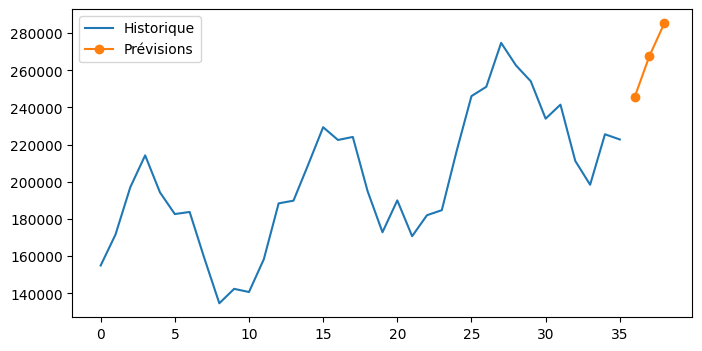

In [17]:
import matplotlib.pyplot as plt

# 3 mois futurs
t_future = np.arange(len(df), len(df) + 3)

future = pd.DataFrame({
    "t": t_future,
    "sin": np.sin(2 * np.pi * t_future / 12),
    "cos": np.cos(2 * np.pi * t_future / 12)
})

previsions = modele.predict(future)

print("Prévisions des 3 prochains mois :")
print(previsions)

# Visualisation
plt.figure(figsize=(8,4))
plt.plot(range(len(df)), y, label="Historique")
plt.plot(t_future, previsions, marker="o", label="Prévisions")
plt.legend()
plt.show()


---
## 📊 Barème récapitulatif (sur 100 pts)

| TD | Exercices | Points |
|----|-----------|--------|
| TD 1 | Ex.1-4 (data QA) | 20 |
| TD 2 | Ex.5-6 (RFM) | 20 |
| TD 3 | Ex.7-8 (churn) | 20 |
| TD 4 | Ex.9-10 (A/B) | 20 |
| TD 5 | Ex.11-12 (prévision) | 20 |
| **Total** | | **100** |

> Seuil de validation : 50/100. Mention : ≥16/20 par TD.